
# MedEvidence AI — Retrieval Evaluation

This notebook evaluates **how accurately MedEvidence AI retrieves relevant medical research from PubMed**.

We will measure retrieval quality using:

- **Hit Rate:** Whether a relevant article appears in the top 5 results.
- **MRR:** How highly relevant articles rank.
- **nDCG:** How well the system ranks articles based on relevance.

The goal is to **measure retrieval performance** and **identify opportunities** to **improve the research assistant.**


In [3]:
from pathlib import Path

# Find the main project folder.
current_folder = Path.cwd().resolve()

if current_folder.name == "evaluation":
    project_folder = current_folder.parent
else:
    project_folder = current_folder

# Check our existing project files.
chroma_path = project_folder / "chroma_db"
pubmed_path = project_folder / "knowledge-base" / "pubmed" / "pubmed_articles.json"

print("Project folder:", project_folder)
print("ChromaDB exists:", chroma_path.exists())
print("PubMed dataset exists:", pubmed_path.exists())

Project folder: C:\Users\Yesh Damania\Projects\llm_engineering\week5\community-contributions\Yesh_Damania_MedEvidence_AI
ChromaDB exists: True
PubMed dataset exists: True


In [4]:
# Inspecting the Existing Vector Database
import chromadb

# Open our existing ChromaDB database.
client = chromadb.PersistentClient(path=str(chroma_path))

# Find the collections stored in the database.
collections = client.list_collections()

for collection in collections:
    print("Collection name:", collection.name)
    print("Total chunks:", collection.count())

    # Inspect one stored embedding to identify its dimensions.
    if collection.count() > 0:
        sample = collection.get(limit=1, include=["embeddings"])
        print("Embedding dimensions:", len(sample["embeddings"][0]))

    print("-" * 40)


Collection name: medevidence_pubmed
Total chunks: 162
Embedding dimensions: 1536
----------------------------------------



## Connecting LangChain to ChromaDB

We have confirmed that our vector database contains 162 research chunks.

We will now connect LangChain to the existing ChromaDB collection using the same embedding model as our main application.

This will allow us to retrieve relevant medical research and evaluate retrieval performance.


In [5]:
from langchain_chroma import Chroma
from langchain_openai import OpenAIEmbeddings

# Initialize the embedding model used for our PubMed research.
embeddings = OpenAIEmbeddings(model="text-embedding-3-small")

# Connect LangChain to our existing ChromaDB collection.
vectorstore = Chroma(
    collection_name="medevidence_pubmed",
    embedding_function=embeddings,
    persist_directory=str(chroma_path)
)

# Verify the connection.
print("Connected to MedEvidence AI ChromaDB!")
print("Total research chunks:", vectorstore._collection.count())


Connected to MedEvidence AI ChromaDB!
Total research chunks: 162



## Creating Evaluation Questions and Ground Truth

To evaluate retrieval performance, we need a dataset containing:

- **Question:** A medical research question submitted to MedEvidence AI.
- **Ground Truth:** The PubMed article(s) that should be retrieved for that question.

We will use PubMed IDs (PMIDs) to identify relevant articles.

This dataset will help us calculate Hit Rate@5, MRR@5, and nDCG@5.

We will also use these questions later to evaluate the quality of generated answers.

In [6]:
import json

# Load our existing PubMed research articles.
with open(pubmed_path, "r", encoding="utf-8") as file:
    pubmed_articles = json.load(file)

print("Dataset type:", type(pubmed_articles).__name__)
print("Total records:", len(pubmed_articles))

# Display the first article to understand its structure.
print(json.dumps(pubmed_articles[0], indent=2, ensure_ascii=False))


Dataset type: list
Total records: 50
{
  "pmid": "33667417",
  "title": "Semaglutide 2·4 mg once a week in adults with overweight or obesity, and type 2 diabetes (STEP 2): a randomised, double-blind, double-dummy, placebo-controlled, phase 3 trial.",
  "abstract": "This trial assessed the efficacy and safety of the GLP-1 analogue once a week subcutaneous semaglutide 2·4 mg versus semaglutide 1·0 mg (the dose approved for diabetes treatment) and placebo for weight management in adults with overweight or obesity, and type 2 diabetes. This double-blind, double-dummy, phase 3, superiority study enrolled adults with a body-mass index of at least 27 kg/m2 and glycated haemoglobin 7-10% (53-86 mmol/mol) who had been diagnosed with type 2 diabetes at least 180 days before screening. Patients were recruited from 149 outpatient clinics in 12 countries across Europe, North America, South America, the Middle East, South Africa, and Asia. Patients were randomly allocated (1:1:1) via an interactive 


## Generating Evaluation Questions

We will generate research questions from our existing PubMed articles.

For each article:
1. Read its title and abstract.
2. Ask an LLM to generate a question that the article can answer.
3. Store the question with the article's PMID.

These question-PMID pairs will form a candidate evaluation dataset.

We will review the questions and their relevant articles before treating them as verified ground truth.


In [7]:
from langchain_openai import ChatOpenAI

# Initialize the LLM for generating evaluation questions.
eval_llm = ChatOpenAI(model="gpt-4o-mini", temperature=0)

evaluation_data = []

# Start with 5 articles to test our evaluation workflow.
for article in pubmed_articles[:5]:

    prompt = f"""
    You are preparing questions for a medical research search evaluation.

    Based on the following PubMed article, generate ONE specific
    medical research question that can be answered using its abstract.

    Do not include the answer.
    Return only the question.

    Title: {article['title']}

    Abstract: {article['abstract']}
    """

    question = eval_llm.invoke(prompt).content.strip()

    evaluation_data.append({
        "question": question,
        "relevant_pmid": article["pmid"],
        "article_title": article["title"]
    })

# Display the generated questions.
for i, item in enumerate(evaluation_data, start=1):
    print(f"\nQuestion {i}: {item['question']}")
    print(f"Relevant PMID: {item['relevant_pmid']}")
    print(f"Article: {item['article_title']}")



Question 1: What was the percentage change in bodyweight from baseline to week 68 for patients receiving semaglutide 2·4 mg compared to those receiving placebo?
Relevant PMID: 33667417
Article: Semaglutide 2·4 mg once a week in adults with overweight or obesity, and type 2 diabetes (STEP 2): a randomised, double-blind, double-dummy, placebo-controlled, phase 3 trial.

Question 2: How does the efficacy of subcutaneously administered tirzepatide compare to semaglutide in reducing HbA1c levels in adults with type 2 diabetes?
Relevant PMID: 38613667
Article: Subcutaneously administered tirzepatide vs semaglutide for adults with type 2 diabetes: a systematic review and network meta-analysis of randomised controlled trials.

Question 3: How does the efficacy of tirzepatide at different doses compare to semaglutide in terms of the change in glycated hemoglobin levels in patients with type 2 diabetes over a 40-week period?
Relevant PMID: 34170647
Article: Tirzepatide versus Semaglutide Once W


## Testing Semantic Search Retrieval

We will test how well MedEvidence AI retrieves relevant PubMed research articles.

For each evaluation question:

1. Search the existing ChromaDB database.
2. Retrieve the top 5 most relevant research chunks.
3. Extract their PubMed IDs (PMIDs).
4. Compare the retrieved PMIDs with the expected PMID.

This will help us understand whether Semantic Search retrieves the expected research before calculating Hit Rate@5, MRR@5, and nDCG@5.


In [8]:
# Store the retrieval results for evaluation.
retrieval_results = []

for i, item in enumerate(evaluation_data, start=1):

    question = item["question"]
    expected_pmid = str(item["relevant_pmid"])

    # Retrieve the top 5 research chunks using Semantic Search.
    retrieved_docs = vectorstore.similarity_search(
        question,
        k=5
    )

    # Extract the PMID associated with each retrieved chunk.
    retrieved_pmids = [
        str(doc.metadata.get("pmid", ""))
        for doc in retrieved_docs
    ]

    # Check whether the expected article was retrieved.
    found = expected_pmid in retrieved_pmids

    retrieval_results.append({
        "question": question,
        "expected_pmid": expected_pmid,
        "retrieved_pmids": retrieved_pmids,
        "found": found
    })

    print(f"\nQuestion {i}: {question}")
    print(f"Expected PMID: {expected_pmid}")
    print(f"Retrieved PMIDs: {retrieved_pmids}")
    print(f"Found in Top 5: {found}")
    print("-" * 60)



Question 1: What was the percentage change in bodyweight from baseline to week 68 for patients receiving semaglutide 2·4 mg compared to those receiving placebo?
Expected PMID: 33667417
Retrieved PMIDs: ['37385278', '33667417', '35131037', '33667417', '35131037']
Found in Top 5: True
------------------------------------------------------------

Question 2: How does the efficacy of subcutaneously administered tirzepatide compare to semaglutide in reducing HbA1c levels in adults with type 2 diabetes?
Expected PMID: 38613667
Retrieved PMIDs: ['38613667', '38613667', '38613667', '40537987', '34170647']
Found in Top 5: True
------------------------------------------------------------

Question 3: How does the efficacy of tirzepatide at different doses compare to semaglutide in terms of the change in glycated hemoglobin levels in patients with type 2 diabetes over a 40-week period?
Expected PMID: 34170647
Retrieved PMIDs: ['34170647', '40537987', '34170647', '38613667', '38613667']
Found in 

For each question, you'll see:
- Expected PMID: The article from which we generated the question.
- Retrieved PMIDs: The articles returned by Semantic Search.
- Found in Top 5: True if the expected article appears among the five retrieved chunks, otherwise False.


## Calculating Hit Rate



### What is Hit Rate?

Hit Rate tells us how often MedEvidence AI finds the correct PubMed research article among the **top 5 search results**.

**In simple terms:**

Imagine we ask MedEvidence AI 5 medical research questions.

For each question, we already have a PubMed article that we expect the system to find.

- If the expected article appears in the top 5 results, it is a **Hit**.
- If the expected article does not appear in the top 5 results, it is a **Miss**.

**Example:**

Suppose we test 5 questions:

- Question 1: Hit
- Question 2: Hit
- Question 3: Miss
- Question 4: Hit
- Question 5: Hit

This means MedEvidence AI successfully found the expected article for **4 out of 5 questions**.

**Formula:**

$$
\text{Hit Rate} = \frac{\text{Successful Retrievals}}{\text{Total Questions}} \times 100
$$

**Calculation:**

$$
\text{Hit Rate} = \frac{4}{5} \times 100 = 80\%
$$

**What does 80% mean?**

It means MedEvidence AI found the expected PubMed article in its top 5 search results for 80% of our test questions.

**Why is this important?**

Before MedEvidence AI can generate a reliable medical research answer, it needs to find relevant research articles.

Hit Rate helps us evaluate how well the retrieval system performs.

**Note:** Hit Rate measures retrieval performance, not whether the final AI-generated medical answer is correct.


In [10]:
# Count questions where the expected PMID was retrieved.
successful_retrievals = sum(
    result["found"] for result in retrieval_results
)

# Count total evaluation questions.
total_questions = len(retrieval_results)

# Calculate Hit Rate@5.
hit_rate_5 = (
    successful_retrievals / total_questions
    if total_questions > 0 else 0
)

print("Semantic Search — Retrieval Evaluation")
print("-" * 40)
print("Total Questions:", total_questions)
print("Successful Retrievals:", successful_retrievals)
print(f"Hit Rate: {hit_rate_5:.2%}")


Semantic Search — Retrieval Evaluation
----------------------------------------
Total Questions: 5
Successful Retrievals: 5
Hit Rate: 100.00%



## Calculating MRR

### What is MRR?

MRR stands for **Mean Reciprocal Rank**.

MRR@5 measures how highly MedEvidence AI ranks the expected PubMed article within the **top 5 search results**.

**In simple terms:**

Imagine searching for a medical research article.

- If the expected article appears at Rank 1, that's excellent.
- If it appears at Rank 3, that's good, but it could be better.
- If it doesn't appear in the top 5, the score is 0.

**Example:**

Suppose we test 5 questions:

| Question | Expected Article Rank | Reciprocal Rank |
|---|---|---|
| Question 1 | 1 | 1.00 |
| Question 2 | 2 | 0.50 |
| Question 3 | Not Found | 0.00 |
| Question 4 | 4 | 0.25 |
| Question 5 | 1 | 1.00 |

**Formula:**

$$
MRR = \frac{1}{N}\sum_{i=1}^{N}\frac{1}{Rank_i}
$$

If the expected article is not found in the top 5, its reciprocal rank is 0.

**Calculation:**

$$
MRR = \frac{1 + 0.5 + 0 + 0.25 + 1}{5} = 0.55
$$

**What does 0.55 mean?**

Our average reciprocal rank is 0.55 out of a maximum possible score of 1.0.

Higher scores mean the expected research articles generally appear closer to the top of the search results.

**Why is this important?**

MedEvidence AI should not only find relevant medical research but also rank the most useful articles near the top.

MRR helps us measure that ranking quality.

**Note:** MRR evaluates retrieval ranking, not the accuracy of the final AI-generated answer.


In [13]:
# Calculate MRR@5 using our existing retrieval results.

reciprocal_ranks = []

for result in retrieval_results:

    expected_pmid = result["expected_pmid"]
    retrieved_pmids = result["retrieved_pmids"]

    # Find the rank of the expected article.
    if expected_pmid in retrieved_pmids:
        rank = retrieved_pmids.index(expected_pmid) + 1
        reciprocal_rank = 1 / rank
    else:
        rank = None
        reciprocal_rank = 0

    reciprocal_ranks.append(reciprocal_rank)

    print(f"Expected PMID: {expected_pmid}")
    print(f"Rank: {rank if rank is not None else 'Not Found'}")
    print(f"Reciprocal Rank: {reciprocal_rank:.2f}")
    print("-" * 40)

# Calculate the average reciprocal rank.
mrr_5 = (
    sum(reciprocal_ranks) / len(reciprocal_ranks)
    if reciprocal_ranks else 0
)

print(f"\nSemantic Search MRR (Mean Reciprocal Rank): {mrr_5:.4f}")

Expected PMID: 33667417
Rank: 2
Reciprocal Rank: 0.50
----------------------------------------
Expected PMID: 38613667
Rank: 1
Reciprocal Rank: 1.00
----------------------------------------
Expected PMID: 34170647
Rank: 1
Reciprocal Rank: 1.00
----------------------------------------
Expected PMID: 39536238
Rank: 1
Reciprocal Rank: 1.00
----------------------------------------
Expected PMID: 40055951
Rank: 1
Reciprocal Rank: 1.00
----------------------------------------

Semantic Search MRR (Mean Reciprocal Rank): 0.9000



## Calculating nDCG

### What is nDCG?

nDCG stands for **Normalized Discounted Cumulative Gain**.

nDCG measures how well MedEvidence AI ranks relevant PubMed articles in the **top 5 search results**.

**In simple terms:**

Imagine MedEvidence AI retrieves five research articles.

We want the most relevant articles to appear near the top, rather than at the bottom.

- A relevant article at Rank 1 receives the highest score.
- A relevant article at Rank 3 receives a lower score.
- If the expected article is missing, the score is 0.

**Example:**

Suppose we know one relevant article for a question.

| Position of Expected Article | nDCG Score |
|---|---|
| Rank 1 | 1.000 |
| Rank 2 | 0.631 |
| Rank 3 | 0.500 |
| Rank 4 | 0.431 |
| Rank 5 | 0.387 |
| Not Found | 0.000 |

**Formula:**

$$
DCG = \sum_{i=1}^{5} \frac{rel_i}{\log_2(i+1)}
$$

Where:
- `rel_i = 1` if the article at rank `i` is relevant.
- `rel_i = 0` if it is not relevant.

We normalize DCG by dividing it by the best possible score (IDCG).

$$
nDCG = \frac{DCG}{IDCG}
$$

**Example Calculation:**

If the only known relevant article appears at Rank 3:

$$
nDCG = \frac{1}{\log_2(3+1)} = 0.50
$$

**What does 0.50 mean?**

The expected article was retrieved, but it appeared at Rank 3 rather than Rank 1.

A higher nDCG score means better ranking of relevant research articles.

**Why is this important?**

MedEvidence AI should prioritize relevant medical studies so that the answer-generation model receives useful evidence first.

nDCG helps us measure how effectively the retrieval system ranks that evidence.

**Note:** This initial evaluation uses one candidate relevant PMID per question. With only one relevant article, nDCG mainly measures its position. A more complete evaluation would label multiple relevant articles for each question.


In [14]:
import math

# Calculate nDCG@5 using our existing retrieval results.
ndcg_scores = []

for result in retrieval_results:

    expected_pmid = result["expected_pmid"]
    retrieved_pmids = result["retrieved_pmids"]

    # Find the position of the expected article.
    if expected_pmid in retrieved_pmids[:5]:
        rank = retrieved_pmids.index(expected_pmid) + 1

        # With one relevant article, the ideal DCG is 1.
        dcg = 1 / math.log2(rank + 1)
        ndcg = dcg
    else:
        rank = None
        ndcg = 0

    ndcg_scores.append(ndcg)

    print(f"Expected PMID: {expected_pmid}")
    print(f"Rank: {rank if rank is not None else 'Not Found'}")
    print(f"nDCG: {ndcg:.4f}")
    print("-" * 40)

# Calculate average nDCG@5 across all questions.
ndcg_5 = (
    sum(ndcg_scores) / len(ndcg_scores)
    if ndcg_scores else 0
)

print(f"\nSemantic Search nDCG (Normalized Discounted Cumulative Gain): {ndcg_5:.4f}")

Expected PMID: 33667417
Rank: 2
nDCG: 0.6309
----------------------------------------
Expected PMID: 38613667
Rank: 1
nDCG: 1.0000
----------------------------------------
Expected PMID: 34170647
Rank: 1
nDCG: 1.0000
----------------------------------------
Expected PMID: 39536238
Rank: 1
nDCG: 1.0000
----------------------------------------
Expected PMID: 40055951
Rank: 1
nDCG: 1.0000
----------------------------------------

Semantic Search nDCG (Normalized Discounted Cumulative Gain): 0.9262



## Retrieval Evaluation Dashboard

We have calculated three retrieval evaluation metrics:

- **Hit Rate:** How often the expected article is found in the top 5 results.
- **MRR:** How highly the expected article appears in the search results.
- **nDCG:** How well the expected article is ranked.

Before building the dashboard, we will remove duplicate PubMed articles from the search results and recalculate our metrics.

We will then visualize the results using a bar chart.

This dashboard will help us understand the performance of MedEvidence AI's Semantic Search.


In [15]:
import math

article_results = []

for item in evaluation_data:
    # Retrieve additional chunks so we can identify 5 unique articles.
    docs = vectorstore.similarity_search(item["question"], k=30)

    unique_pmids = []

    for doc in docs:
        pmid = str(doc.metadata.get("pmid", ""))

        # Keep each article only once.
        if pmid and pmid not in unique_pmids:
            unique_pmids.append(pmid)

        if len(unique_pmids) == 5:
            break

    expected_pmid = str(item["relevant_pmid"])

    if expected_pmid in unique_pmids:
        rank = unique_pmids.index(expected_pmid) + 1
    else:
        rank = None

    article_results.append({
        "question": item["question"],
        "expected_pmid": expected_pmid,
        "retrieved_pmids": unique_pmids,
        "rank": rank,
        "hit": 1 if rank else 0,
        "mrr": 1 / rank if rank else 0,
        "ndcg": 1 / math.log2(rank + 1) if rank else 0
    })

# Calculate average evaluation scores.
total = len(article_results)

hit_rate_5 = sum(r["hit"] for r in article_results) / total
mrr_5 = sum(r["mrr"] for r in article_results) / total
ndcg_5 = sum(r["ndcg"] for r in article_results) / total

print(f"Article-Level Hit Rate@5: {hit_rate_5:.2%}")
print(f"Article-Level MRR@5: {mrr_5:.4f}")
print(f"Article-Level nDCG@5: {ndcg_5:.4f}")


Article-Level Hit Rate@5: 100.00%
Article-Level MRR@5: 0.9000
Article-Level nDCG@5: 0.9262


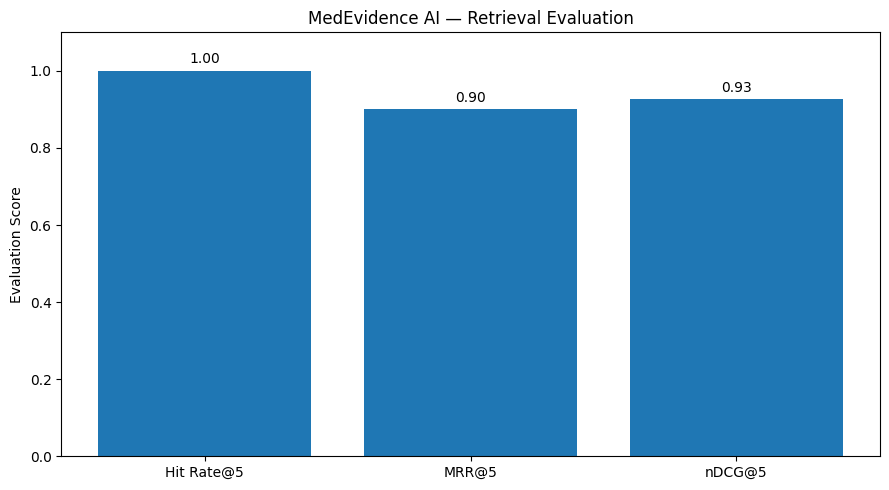

In [16]:
# Visualize the Dashboard
import matplotlib.pyplot as plt

# Prepare the retrieval metrics.
metrics = ["Hit Rate@5", "MRR@5", "nDCG@5"]
scores = [hit_rate_5, mrr_5, ndcg_5]

# Create the retrieval evaluation dashboard.
plt.figure(figsize=(9, 5))

bars = plt.bar(metrics, scores)

plt.title("MedEvidence AI — Retrieval Evaluation")
plt.ylabel("Evaluation Score")
plt.ylim(0, 1.1)

# Display each score above its bar.
for bar, score in zip(bars, scores):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        score + 0.02,
        f"{score:.2f}",
        ha="center"
    )

plt.tight_layout()
plt.show()



## Answer Quality Evaluation

### What is Answer Quality Evaluation?

Answer Quality Evaluation measures how good the final answers generated by MedEvidence AI are.

Finding the correct research article is only the first step. Our AI must also use that research to produce useful, evidence-supported answers.

We will evaluate three metrics:

**1. Accuracy:** Does the generated answer make claims that are supported by the retrieved PubMed research?

**2. Completeness:** Does the answer cover the important findings needed to answer the question?

**3. Relevance:** Does the answer directly address the user's medical research question?

### How will we evaluate the answers?

We will use an approach called **LLM as a Judge**.

In simple terms, one AI model generates an answer, and another AI model evaluates that answer using predefined criteria.

Each metric will receive a score from 1 to 5.

| Score | Meaning |
|---|---|
| 1 | Very Poor |
| 2 | Poor |
| 3 | Average |
| 4 | Good |
| 5 | Excellent |

### Why is this important?

MedEvidence AI is a medical research assistant. Its answers should be relevant, complete, and supported by scientific evidence.

Evaluating these qualities helps us identify weaknesses and improve the system.

**Important:** An LLM judge provides an automated quality estimate, not a clinical verification or guarantee of medical correctness.


In [17]:
from langchain_openai import ChatOpenAI
from langchain_core.prompts import ChatPromptTemplate

# Initialize the model that will evaluate generated answers.
judge_llm = ChatOpenAI(
    model="gpt-4o-mini",
    temperature=0
)

# Define the criteria used to evaluate each answer.
judge_prompt = ChatPromptTemplate.from_messages([
    ("system", """
You are an evaluator for a medical research assistant.

Your task is to evaluate a generated answer using:
1. The user's research question.
2. The retrieved PubMed evidence.
3. The generated answer.

Score each metric from 1 to 5.

Accuracy:
5 = All important medical claims are supported by the evidence.
3 = Some claims are supported, but others are unclear.
1 = Important claims contradict or lack support from the evidence.

Completeness:
5 = Covers all important findings available in the evidence.
3 = Covers some important findings but misses others.
1 = Misses most important findings.

Relevance:
5 = Directly and clearly answers the question.
3 = Partially answers the question.
1 = Does not address the question.

Do not assume unsupported medical claims are correct.
Evaluate only against the supplied evidence.

Return ONLY valid JSON in this format:
{{
    "accuracy": 1,
    "completeness": 1,
    "relevance": 1,
    "reason": "Brief explanation of the scores"
}}
"""),
    ("human", """
Question:
{question}

Retrieved PubMed Evidence:
{evidence}

Generated Answer:
{answer}
""")
])

print("Answer Quality Evaluation Judge initialized!")


Answer Quality Evaluation Judge initialized!



## Generating and Evaluating Research Answers

### What are we doing?

We have already created an LLM judge to evaluate the quality of MedEvidence AI's answers.

Now we will test it using a real medical research question.

**Our process:**

1. Select a question from our evaluation dataset.
2. Retrieve relevant PubMed research using Semantic Search.
3. Generate an answer using the retrieved evidence.
4. Ask our LLM judge to evaluate the answer.
5. Display Accuracy, Completeness, and Relevance scores.

### Why is this important?

A research assistant might retrieve the correct articles but still generate an incomplete or unsupported answer.

By evaluating both retrieval and answer quality, we can better understand how reliable MedEvidence AI is.

**Note:** Accuracy here means evidence support as estimated by the LLM judge. It is not independently verified clinical accuracy.

In [18]:
from langchain_core.prompts import ChatPromptTemplate
from langchain_openai import ChatOpenAI

# Select the first evaluation question.
test_question = evaluation_data[0]["question"]

# Retrieve the top 5 research chunks.
test_docs = vectorstore.similarity_search(test_question, k=5)

# Prepare the retrieved evidence.
test_evidence = "\n\n".join(
    f"PMID: {doc.metadata.get('pmid', 'Unknown')}\n"
    f"Research: {doc.page_content}"
    for doc in test_docs
)

# Create an evidence-grounded answer generation prompt.
answer_prompt = ChatPromptTemplate.from_messages([
    ("system", """
You are MedEvidence AI, a medical research assistant.

Answer the research question using only the provided PubMed evidence.

Explain the findings clearly and cite relevant PubMed IDs (PMIDs).

Do not invent findings or unsupported medical claims.

If the evidence is insufficient, explain what is missing.
"""),
    ("human", """
Research Question:
{question}

PubMed Evidence:
{evidence}
""")
])

answer_llm = ChatOpenAI(model="gpt-4o-mini", temperature=0)

# Generate the research answer.
answer_chain = answer_prompt | answer_llm

generated_answer = answer_chain.invoke({
    "question": test_question,
    "evidence": test_evidence
}).content

print("QUESTION:\n", test_question)
print("\nGENERATED ANSWER:\n", generated_answer)


QUESTION:
 What was the percentage change in bodyweight from baseline to week 68 for patients receiving semaglutide 2·4 mg compared to those receiving placebo?

GENERATED ANSWER:
 The percentage change in bodyweight from baseline to week 68 for patients receiving semaglutide 2.4 mg compared to those receiving placebo is as follows:

- **Semaglutide 2.4 mg**: The mean bodyweight change was **-9.6%** (SE 0.4).
- **Placebo**: The mean bodyweight change was **-3.4%** (SE 0.4).

The estimated treatment difference between semaglutide 2.4 mg and placebo was **-6.2 percentage points** (95% CI -7.3 to -5.2; p<0.0001) (PMID: 33667417).

Additionally, a higher proportion of patients on semaglutide 2.4 mg achieved a weight reduction of at least 5% compared to those on placebo: **68.8%** (267 out of 388) of the semaglutide group versus **28.5%** (107 out of 376) of the placebo group (odds ratio 4.88, 95% CI 3.58 to 6.64; p<0.0001) (PMID: 33667417).

In summary, patients receiving semaglutide 2.4 mg

In [19]:
# Evaluate the Generated answer
import json

# Combine our evaluation prompt with the LLM judge.
judge_chain = judge_prompt | judge_llm

# Evaluate the generated answer.
judge_response = judge_chain.invoke({
    "question": test_question,
    "evidence": test_evidence,
    "answer": generated_answer
})

# Convert the judge's JSON response into Python data.
judge_text = judge_response.content.strip()

# Remove Markdown code fences if the model includes them.
if judge_text.startswith("```"):
    judge_text = judge_text.split("\n", 1)[1]
    judge_text = judge_text.rsplit("```", 1)[0].strip()

evaluation_scores = json.loads(judge_text)

print("MedEvidence AI — Answer Quality Evaluation")
print("-" * 45)
print(f"Accuracy: {evaluation_scores['accuracy']}/5")
print(f"Completeness: {evaluation_scores['completeness']}/5")
print(f"Relevance: {evaluation_scores['relevance']}/5")
print(f"\nJudge Explanation: {evaluation_scores['reason']}")


MedEvidence AI — Answer Quality Evaluation
---------------------------------------------
Accuracy: 5/5
Completeness: 5/5
Relevance: 5/5

Judge Explanation: The generated answer accurately presents the percentage change in bodyweight for both semaglutide 2.4 mg and placebo, supported by the evidence from the retrieved PubMed articles. It includes all important findings, such as the estimated treatment difference and the proportion of patients achieving at least a 5% weight reduction, directly addressing the user's research question.


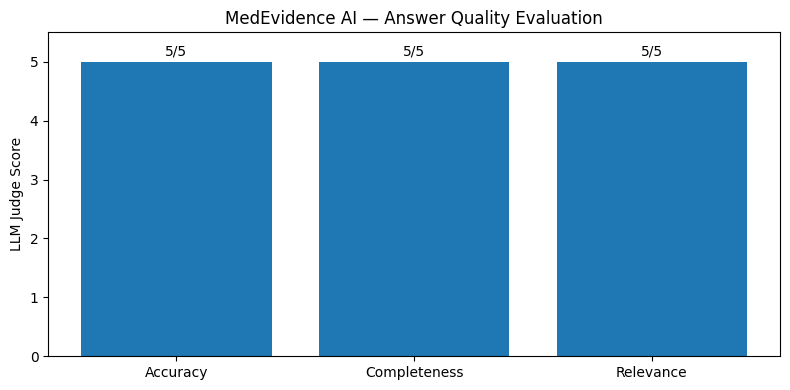

In [20]:
import matplotlib.pyplot as plt

# Reuse the scores from Step 10.12.
metrics = ["Accuracy", "Completeness", "Relevance"]

scores = [
    evaluation_scores["accuracy"],
    evaluation_scores["completeness"],
    evaluation_scores["relevance"]
]

# Visualize the existing evaluation results.
plt.figure(figsize=(8, 4))

bars = plt.bar(metrics, scores)

plt.title("MedEvidence AI — Answer Quality Evaluation")
plt.ylabel("LLM Judge Score")
plt.ylim(0, 5.5)

for bar, score in zip(bars, scores):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        score + 0.1,
        f"{score}/5",
        ha="center"
    )

plt.tight_layout()
plt.show()



## Preparing the Evaluation Dashboard App

We will create a separate Gradio application to display our evaluation results.

The dashboard will show:

1. Retrieval Quality — Hit Rate@5, MRR@5, and nDCG@5.
2. Answer Quality — Accuracy, Completeness, and Relevance.

We will save the scores as a JSON file so the dashboard can load them without rerunning retrieval or LLM evaluations.

The answer quality scores currently represent one evaluated question.


In [21]:
import json

# Prepare the scores we already calculated.
dashboard_results = {
    "retrieval": {
        "hit_rate_5": hit_rate_5,
        "mrr_5": mrr_5,
        "ndcg_5": ndcg_5,
        "questions_evaluated": len(article_results)
    },
    "answer_quality": {
        "accuracy": evaluation_scores["accuracy"],
        "completeness": evaluation_scores["completeness"],
        "relevance": evaluation_scores["relevance"],
        "questions_evaluated": 1
    }
}

# Save the results inside our evaluation folder.
results_path = project_folder / "evaluation" / "evaluation_results.json"

with open(results_path, "w", encoding="utf-8") as file:
    json.dump(dashboard_results, file, indent=4)

print("Evaluation results saved successfully!")
print("File:", results_path)


Evaluation results saved successfully!
File: C:\Users\Yesh Damania\Projects\llm_engineering\week5\community-contributions\Yesh_Damania_MedEvidence_AI\evaluation\evaluation_results.json



## Comparing Semantic Search and LLM Reranking

### What are we doing?

MedEvidence AI supports two methods for finding medical research:

**1. Semantic Search**

Uses vector embeddings to find research chunks that are similar to the user's question.

**2. LLM Reranking**

First retrieves 8 research chunks using Semantic Search.

Then an LLM examines those chunks and rearranges them based on their relevance to the question.

Finally, it selects the top 5 chunks.

### Why are we comparing them?

We want to understand whether LLM Reranking improves the quality of retrieved medical research.

We will use the same evaluation questions for both methods.

We will compare:

- Hit Rate@5
- MRR@5
- nDCG@5

This will help us decide whether the additional LLM reranking step improves retrieval performance.

**Important:** Reranking can change the order of the 8 candidate chunks, but it cannot retrieve articles that were not among those original candidates.

In [22]:
import json

from langchain_core.prompts import ChatPromptTemplate
from langchain_openai import ChatOpenAI

# Retrieve the same 8 candidates used by the main application.
candidate_retriever = vectorstore.as_retriever(
    search_type="similarity",
    search_kwargs={"k": 8}
)

# Use the same reranking instructions as Step 7.
rerank_prompt = ChatPromptTemplate.from_messages([
    (
        "system",
        """
You are a medical research retrieval assistant.

Rank the provided research chunks by relevance to the question.

Prioritize:
- Research directly addressing the question.
- Findings and outcomes relevant to the question.
- Specific evidence over general background information.

Do not invent findings or use outside knowledge.

Return ONLY a JSON object in this format:
{{"ranking": [1, 3, 2]}}

Include every provided chunk number exactly once.
"""
    ),
    (
        "human",
        """
Question:
{question}

Research Chunks:
{context}
"""
    )
])

# Use the same LLM configuration as the main notebook.
rerank_llm = ChatOpenAI(model="gpt-4o-mini", temperature=0)


def rerank_research(question, docs, top_k=5):

    if not docs:
        return []

    # Prepare numbered research chunks for the LLM.
    context = "\n\n".join(
        f"Chunk {i}\n"
        f"Title: {doc.metadata['title']}\n"
        f"Content: {doc.page_content}"
        for i, doc in enumerate(docs, start=1)
    )

    messages = rerank_prompt.invoke({
        "question": question,
        "context": context
    })

    try:
        response = rerank_llm.invoke(messages)
        ranking = json.loads(response.content)["ranking"]

        # Verify the ranking contains each chunk exactly once.
        expected = set(range(1, len(docs) + 1))

        if (
            not isinstance(ranking, list)
            or len(ranking) != len(docs)
            or any(type(i) is not int for i in ranking)
            or set(ranking) != expected
        ):
            raise ValueError("Invalid reranking response")

        return [docs[i - 1] for i in ranking][:top_k]

    except (ValueError, KeyError, TypeError, AttributeError):
        print("Invalid reranking output. Using original retrieval order.")
        return docs[:top_k]


print("LLM Reranking evaluation pipeline ready!")


LLM Reranking evaluation pipeline ready!


In [23]:
# Select one existing evaluation question.
question = evaluation_data[0]["question"]

# Method 1: Semantic Search.
semantic_docs = candidate_retriever.invoke(question)[:5]

# Method 2: Rerank the same 8 candidate chunks.
candidates = candidate_retriever.invoke(question)
reranked_docs = rerank_research(question, candidates, top_k=5)

print("QUESTION:")
print(question)

print("\nSEMANTIC SEARCH — TOP 5 PMIDs")
print([doc.metadata.get("pmid") for doc in semantic_docs])

print("\nLLM RERANKING — TOP 5 PMIDs")
print([doc.metadata.get("pmid") for doc in reranked_docs])


QUESTION:
What was the percentage change in bodyweight from baseline to week 68 for patients receiving semaglutide 2·4 mg compared to those receiving placebo?

SEMANTIC SEARCH — TOP 5 PMIDs
['37385278', '33667417', '35131037', '33667417', '35131037']

LLM RERANKING — TOP 5 PMIDs
['33667417', '33667417', '35131037', '37385278', '38330988']



## Comparing Retrieval Performance

### What are we doing?

We will compare two retrieval methods:

1. **Semantic Search:** Ranks research chunks using embedding similarity.
2. **LLM Reranking:** Uses an LLM to reorder the same 8 candidate chunks and selects the top 5.

### How will we compare them?

We will evaluate both methods using the same 5 research questions.

For each method, we calculate:

- **Hit Rate@5:** How often the expected PubMed article is found.
- **MRR@5:** How highly the expected article is ranked.
- **nDCG@5:** How well the expected article is positioned.

### Why is this important?

LLM Reranking requires an additional model call, which increases cost and processing time.

We want to determine whether that additional step improves retrieval quality enough to justify its use.

**Note:** This comparison uses candidate expected PMIDs and only five questions, so the results are preliminary.


In [24]:
import math
import pandas as pd

# Convert ranked chunks into unique PubMed article IDs.
def unique_article_pmids(docs, limit=5):
    pmids = []

    for doc in docs:
        pmid = str(doc.metadata.get("pmid", ""))

        if pmid and pmid not in pmids:
            pmids.append(pmid)

        if len(pmids) == limit:
            break

    return pmids


# Calculate retrieval metrics for one expected article.
def calculate_metrics(expected_pmid, retrieved_pmids):

    if expected_pmid in retrieved_pmids:
        rank = retrieved_pmids.index(expected_pmid) + 1
    else:
        rank = None

    return {
        "Hit Rate@5": 1 if rank else 0,
        "MRR@5": 1 / rank if rank else 0,
        "nDCG@5": 1 / math.log2(rank + 1) if rank else 0
    }


comparison_results = []

for i, item in enumerate(evaluation_data, start=1):

    question = item["question"]
    expected_pmid = str(item["relevant_pmid"])

    # Retrieve the same 8 candidate chunks for both methods.
    candidates = candidate_retriever.invoke(question)

    # Semantic Search uses the original similarity ranking.
    semantic_pmids = unique_article_pmids(candidates[:5])

    # LLM Reranking reorders the candidates before selecting 5.
    reranked_docs = rerank_research(question, candidates, top_k=5)
    reranked_pmids = unique_article_pmids(reranked_docs)

    # Calculate scores for both methods.
    semantic_scores = calculate_metrics(expected_pmid, semantic_pmids)
    reranked_scores = calculate_metrics(expected_pmid, reranked_pmids)

    comparison_results.append({
        "Question": i,
        "Method": "Semantic Search",
        **semantic_scores
    })

    comparison_results.append({
        "Question": i,
        "Method": "LLM Reranking",
        **reranked_scores
    })

    print(f"Question {i}/{len(evaluation_data)} evaluated.")


# Create a table containing average scores for both methods.
comparison_df = pd.DataFrame(comparison_results)

comparison_summary = (
    comparison_df
    .groupby("Method")[
        ["Hit Rate@5", "MRR@5", "nDCG@5"]
    ]
    .mean()
    .round(4)
)

display(comparison_summary)


Question 1/5 evaluated.
Question 2/5 evaluated.
Question 3/5 evaluated.
Question 4/5 evaluated.
Question 5/5 evaluated.


,Hit Rate@5,MRR@5,nDCG@5
Method,,,
LLM Reranking,1.0,1.0,1.0000
Semantic Search,1.0,0.9,0.9262


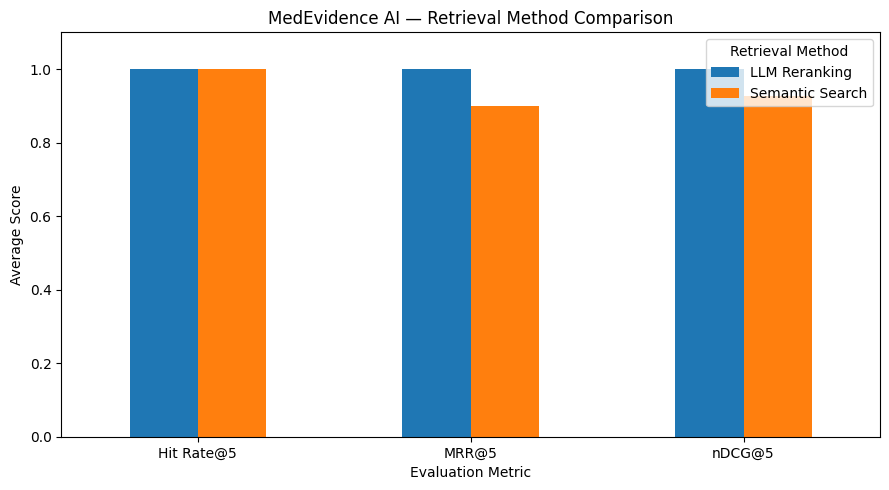

In [25]:
# Visualize the Comparision

import matplotlib.pyplot as plt

# Compare the average retrieval scores.
ax = comparison_summary.T.plot(
    kind="bar",
    figsize=(9, 5),
    rot=0
)

ax.set_title("MedEvidence AI — Retrieval Method Comparison")
ax.set_xlabel("Evaluation Metric")
ax.set_ylabel("Average Score")
ax.set_ylim(0, 1.1)

ax.legend(title="Retrieval Method")

plt.tight_layout()
plt.show()


In [ ]:
# Saving Retrieval Comparison Results, 
# Semantic Search -- relevant search

# Open our existing evaluation results file.
results_path = project_folder / "evaluation" / "evaluation_results.json"

with open(results_path, "r", encoding="utf-8") as file:
    dashboard_results = json.load(file)

# Convert the comparison table into JSON-friendly dictionaries.
comparison_scores = {}

for method in comparison_summary.index:

    method_key = (
        "semantic_search"
        if method == "Semantic Search"
        else "llm_reranking"
    )

    comparison_scores[method_key] = {
        "hit_rate_5": float(comparison_summary.loc[method, "Hit Rate@5"]),
        "mrr_5": float(comparison_summary.loc[method, "MRR@5"]),
        "ndcg_5": float(comparison_summary.loc[method, "nDCG@5"])
    }

# Add the new comparison without removing previous evaluations.
dashboard_results["retrieval_comparison"] = {
    "semantic_search": comparison_scores["semantic_search"],
    "llm_reranking": comparison_scores["llm_reranking"],
    "questions_evaluated": len(evaluation_data)
}

# Save the updated results.
with open(results_path, "w", encoding="utf-8") as file:
    json.dump(dashboard_results, file, indent=4)

print("Retrieval comparison results saved successfully!")
print("File:", results_path)

print("\nSaved comparison:")
print(json.dumps(dashboard_results["retrieval_comparison"], indent=4))


Retrieval comparison results saved successfully!
File: C:\Users\Yesh Damania\Projects\llm_engineering\week5\community-contributions\Yesh_Damania_MedEvidence_AI\evaluation\evaluation_results.json

Saved comparison:
{
    "semantic_search": {
        "hit_rate_5": 1.0,
        "mrr_5": 0.9,
        "ndcg_5": 0.9262
    },
    "llm_reranking": {
        "hit_rate_5": 1.0,
        "mrr_5": 1.0,
        "ndcg_5": 1.0
    },
    "questions_evaluated": 5
}



## Interpreting Retrieval Evaluation Results

### Objective

Determine whether LLM Reranking improves research retrieval compared with Semantic Search.

We compare:

- Hit Rate@5: Whether the expected article appears in the retrieved results.
- MRR@5: How highly the expected article is ranked.
- nDCG@5: How well the expected article is positioned.

### Interpretation

Higher scores indicate better retrieval performance.

LLM Reranking is useful when it improves the ranking of relevant research articles.

However, reranking introduces additional LLM calls, increasing latency and cost.

Our evaluation uses only five automatically generated questions with candidate relevance labels. Therefore, the findings are preliminary rather than a clinically validated benchmark.


In [27]:
# Interpret retrieval comparison results

metrics = ["Hit Rate@5", "MRR@5", "nDCG@5"]

print("MEDEVIDENCE AI — RETRIEVAL EVALUATION SUMMARY")
print("=" * 55)

for metric in metrics:

    semantic_score = comparison_summary.loc[
        "Semantic Search", metric
    ]

    reranking_score = comparison_summary.loc[
        "LLM Reranking", metric
    ]

    difference = reranking_score - semantic_score

    if difference > 0:
        result = "IMPROVED"
    elif difference < 0:
        result = "DECREASED"
    else:
        result = "UNCHANGED"

    print(f"\n{metric}")
    print(f"Semantic Search : {semantic_score:.4f}")
    print(f"LLM Reranking   : {reranking_score:.4f}")
    print(f"Difference      : {difference:+.4f}")
    print(f"Result          : {result}")

print("\n" + "=" * 55)
print("Evaluation completed on", len(evaluation_data), "questions.")
print("Results are preliminary and not clinically validated.")


MEDEVIDENCE AI — RETRIEVAL EVALUATION SUMMARY

Hit Rate@5
Semantic Search : 1.0000
LLM Reranking   : 1.0000
Difference      : +0.0000
Result          : UNCHANGED

MRR@5
Semantic Search : 0.9000
LLM Reranking   : 1.0000
Difference      : +0.1000
Result          : IMPROVED

nDCG@5
Semantic Search : 0.9262
LLM Reranking   : 1.0000
Difference      : +0.0738
Result          : IMPROVED

Evaluation completed on 5 questions.
Results are preliminary and not clinically validated.



## Evaluation Findings and Conclusion

### Results

MedEvidence AI was evaluated using five research questions generated from the PubMed knowledge base.

Two retrieval approaches were compared:

1. Semantic Search using vector embeddings.
2. LLM Reranking using eight semantic-search candidates, reordered by an LLM.

| Metric | Semantic Search | LLM Reranking |
|---|---|---|
| Hit Rate@5 | 1.0000 | 1.0000 |
| MRR@5 | 0.9000 | 1.0000 |
| nDCG@5 | 0.9262 | 1.0000 |

### Key Findings

- Both approaches achieved a 100% Hit Rate@5.
- LLM Reranking improved MRR@5 by 11.1% relative to Semantic Search.
- LLM Reranking improved nDCG@5 by approximately 8.0% relative to Semantic Search.
- Reranking placed the expected PubMed article at rank 1 for all five evaluated questions.

### Limitations

- The evaluation dataset contains only five questions.
- Questions were generated using an LLM rather than collected from real users.
- Each question has one expected PubMed article, rather than independently assessed relevance labels for multiple articles.
- The comparison evaluates retrieval ranking, not medical correctness or clinical safety.
- Reranking requires additional LLM inference, introducing latency and cost that were not measured.

### Conclusion

On this small preliminary benchmark, LLM Reranking improved the ranking of expected PubMed research articles while maintaining the same retrieval hit rate.

The results support further investigation of reranking as part of MedEvidence AI's retrieval pipeline.

A larger, independently labeled evaluation dataset and latency measurements are needed before drawing broader conclusions.